## 01-Classical Classifier Baseline
In this notebook, we will do a simple baseline classification using classicial method (Tfidf and logistic regression)

In [72]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import precision_recall_fscore_support, f1_score, classification_report, mean_squared_error
from sklearn.linear_model import LogisticRegression, RidgeCV 
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

In [73]:
# load train and dev set

# please point to correct downloaded transcribed folders of the original dataset
data_path = "../../../data/" 

train_fname = data_path + "splits/train_50pc.csv"
dev_fname = data_path + "splits/dev_50pc.csv"

train_df = pd.read_csv(train_fname)
dev_df = pd.read_csv(dev_fname)

print("Train len =", len(train_df))
print("Dev df =", len(dev_df))

Train len = 83
Dev df = 83


In [74]:
train_df.head()

,file_id,text,target,mmse
0,adrso021,"Everything you see going on in this picture, g...",CN,28
1,adrso265,"Now you just look at the picture. Okay, this i...",CN,30
2,adrso237,Tell me everything that you see going on in th...,AD,20
3,adrso197,Girls and boys getting her one that stores sto...,AD,20
4,adrso017,"All right, we have a few more tasks to go thro...",CN,30


In [75]:
dev_df.head()

,file_id,text,target,mmse
0,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD,11
1,adrso028,She will find her mother worship trying to dis...,AD,18
2,adrso032,What's going on well the children are climbing...,AD,25
3,adrso035,Okay here's the picture tell me I'll tell you ...,AD,24
4,adrso036,Tell me what's going on\n\n\n\nall the action ...,AD,10


### Pre-processing
We will lowercase the text for better efficiency

In [76]:
train_df["text_lower"] = train_df["text"].apply(lambda text: text.lower().strip())
dev_df["text_lower"] = dev_df["text"].apply(lambda text: text.lower().strip())

In [77]:
train_df.head()

,file_id,text,target,mmse,text_lower
0,adrso021,"Everything you see going on in this picture, g...",CN,28,"everything you see going on in this picture, g..."
1,adrso265,"Now you just look at the picture. Okay, this i...",CN,30,"now you just look at the picture. okay, this i..."
2,adrso237,Tell me everything that you see going on in th...,AD,20,tell me everything that you see going on in th...
3,adrso197,Girls and boys getting her one that stores sto...,AD,20,girls and boys getting her one that stores sto...
4,adrso017,"All right, we have a few more tasks to go thro...",CN,30,"all right, we have a few more tasks to go thro..."


In [78]:
dev_df.head()

,file_id,text,target,mmse,text_lower
0,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD,11,tell me everything that's going on\n\n\n\nthe ...
1,adrso028,She will find her mother worship trying to dis...,AD,18,she will find her mother worship trying to dis...
2,adrso032,What's going on well the children are climbing...,AD,25,what's going on well the children are climbing...
3,adrso035,Okay here's the picture tell me I'll tell you ...,AD,24,okay here's the picture tell me i'll tell you ...
4,adrso036,Tell me what's going on\n\n\n\nall the action ...,AD,10,tell me what's going on\n\n\n\nall the action ...


### Build Tfidf Vectorizer

We can use Tfidf Vectorizer to convert text to a fixed-length vector

In [79]:
vectorizer = TfidfVectorizer()


corpus = train_df["text_lower"]
print(len(corpus))
print("Building Tfidf Vectorizer...")
X_train = vectorizer.fit_transform(corpus)
print("Completed")

83
Building Tfidf Vectorizer...
Completed


In [80]:
print(X_train.shape)

(83, 949)


### Train Logistic regression using Tfidf vectorizer

We can now train a simple logistic regression classifier using processed X_train

In [81]:
X_train = vectorizer.fit_transform(train_df["text_lower"])
y_train = train_df["target"]

print("Training logistic classifier...")
clf = LogisticRegression(random_state=42, 
                        ).fit(X_train, y_train)
print("Completed")

Training logistic classifier...
Completed


In [82]:
# getting score on train set
train_score = clf.score(X_train, y_train)
print(f"Train accuracy = {train_score*100:.2f} %")

Train accuracy = 96.39 %


### Get accuracy using cross validation

In [83]:
print("Performing cross-validation...")
scores = cross_val_score(clf, X_train, y_train, cv=5)
print("Completed")
print(scores)
print("Average =", np.average(scores))

Performing cross-validation...
Completed
[0.41176471 0.70588235 0.64705882 0.75       0.6875    ]
Average = 0.6404411764705882


In [84]:
# get precision / recall / f1
y_pred = clf.predict(X_train)
print(classification_report(y_train, y_pred, target_names=["AD", "CN"]))

              precision    recall  f1-score   support

          AD       0.94      1.00      0.97        47
          CN       1.00      0.92      0.96        36

    accuracy                           0.96        83
   macro avg       0.97      0.96      0.96        83
weighted avg       0.97      0.96      0.96        83



### Now we can evaluate on dev set

In [85]:
X_dev = vectorizer.transform(dev_df["text_lower"])
y_dev = dev_df["target"]
print("X_dev shape =", X_dev.shape)
print("y_dev len =", len(y_dev))

X_dev shape = (83, 949)
y_dev len = 83


In [86]:
dev_score = clf.score(X_dev, y_dev)
print(f"Dev accuracy = {dev_score*100:.2f} %")

Dev accuracy = 73.49 %


In [87]:
y_pred = clf.predict(X_dev)
print(classification_report(y_dev, y_pred, target_names=["AD", "CN"]))

              precision    recall  f1-score   support

          AD       0.67      0.88      0.76        40
          CN       0.84      0.60      0.70        43

    accuracy                           0.73        83
   macro avg       0.76      0.74      0.73        83
weighted avg       0.76      0.73      0.73        83



### Process prediction for test set

In [88]:
test_fname = data_path + "splits/test_text.csv"

test_df = pd.read_csv(test_fname)
print("Test df =", len(test_df))
test_df["text_lower"] = test_df["text"].apply(lambda text: text.lower().strip())
test_df.head()

Test df = 71


,ID,Prediction,text,text_lower
0,adrsdt15,NaN,"I see oh boy, almost falling on a stool trying...","i see oh boy, almost falling on a stool trying..."
1,adrsdt40,NaN,Well the kids are trying to get the cookies an...,well the kids are trying to get the cookies an...
2,adrsdt26,NaN,"Okay, this is a family setting in a kitchen an...","okay, this is a family setting in a kitchen an..."
3,adrsdt67,NaN,"Oh, what do I see in this picture? This remind...","oh, what do i see in this picture? this remind..."
4,adrsdt58,NaN,While the young boy is reaching for a cookie j...,while the young boy is reaching for a cookie j...


In [89]:
X_test = vectorizer.transform(test_df["text_lower"])
test_df["Prediction"] = clf.predict(X_test)
test_df.head()

,ID,Prediction,text,text_lower
0,adrsdt15,CN,"I see oh boy, almost falling on a stool trying...","i see oh boy, almost falling on a stool trying..."
1,adrsdt40,CN,Well the kids are trying to get the cookies an...,well the kids are trying to get the cookies an...
2,adrsdt26,CN,"Okay, this is a family setting in a kitchen an...","okay, this is a family setting in a kitchen an..."
3,adrsdt67,AD,"Oh, what do I see in this picture? This remind...","oh, what do i see in this picture? this remind..."
4,adrsdt58,AD,While the young boy is reaching for a cookie j...,while the young boy is reaching for a cookie j...


In [90]:
# convert to 0/1 to be consistent to ground truth
label2binary = lambda label: "0" if label=="0" or label.lower().strip() == "cn" else "1"
assert label2binary("CN") == "0"
assert label2binary("AD") == "1"
assert label2binary("0") == "0"
assert label2binary("1") == "1"

print("Passed")

Passed


In [91]:
# apply to prediction column
test_df["Prediction"] = test_df["Prediction"].apply(label2binary)
# write to prediction output file
output_path = "../../evaluation/"
fname = "test_results_task1_classical.csv"
output_df = test_df.drop(columns=["text", "text_lower"])
output_df.head()

,ID,Prediction
0,adrsdt15,0
1,adrsdt40,0
2,adrsdt26,0
3,adrsdt67,1
4,adrsdt58,1


In [92]:
output_df.to_csv(output_path + fname,
                 index=False
                )
print("Completed")

Completed


### Output from evaluation scripts

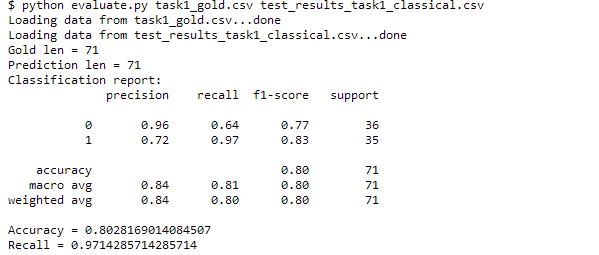

### Train Ridge 

We can now train a ridge regression model after reading in the task2 gold labels

In [93]:
folder = "../../evaluation/"
fname = "task2_gold.csv"
y_test_gold = pd.read_csv(folder + fname)

In [94]:
print("Training ridge pipeline...")
pipeline = make_pipeline(vectorizer, RidgeCV(cv=10))
pipeline.fit(train_df["text_lower"], train_df["mmse"])
print("Completed")
y_pred = pipeline.predict(train_df["text_lower"])
print("Training RMSE: ", np.sqrt(mean_squared_error(train_df["mmse"], y_pred)))

Training ridge pipeline...
Completed
Training RMSE:  3.333334053837445


In [95]:
y_pred = pipeline.predict(dev_df["text_lower"])
print("Dev RMSE: ", np.sqrt(mean_squared_error(dev_df["mmse"], y_pred)))

Dev RMSE:  5.498544043763551


In [96]:
y_test = pipeline.predict(test_df["text_lower"])
test_df["mmse"] = y_test
assert sum(y_test_gold["ID"] != test_df["ID"]) == 0
print("Test RMSE: ", np.sqrt(mean_squared_error(y_test_gold["MMSE"], y_test)))

Test RMSE:  4.761243135353185
